# Practice 12 — Instance Segmentation

**Goal:** run a pretrained segmentation model the same way as a detector, read the masks it adds, and score it with box and mask mAP.

| Task | Output per object | Numbers per object |
|:---|:---|:---|
| Classification | one label for the whole image | 1 class index |
| Object detection | one axis-aligned box | 4 coordinates + class + confidence |
| Instance segmentation | one per-pixel mask | a 0/1 grid + class + confidence |

- Nothing is trained here → the weights arrive pretrained on the 80 COCO classes

---
## Step 0. Setup

- `ultralytics` → the YOLO models with their `predict` and `val` methods
- A path given to `YOLO(...)` → the weights are downloaded there, not into the working directory

In [1]:
import subprocess
import sys

try:
    import ultralytics
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics'], check=True)
    import ultralytics

print(f'ultralytics {ultralytics.__version__}')

ultralytics 8.4.194


In [2]:
import urllib.request
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

np.random.seed(42)
torch.manual_seed(42)

# the weights and the images are saved under these two folders; val() writes its runs to runs/
BUILD = Path('build')
DATA = Path('data')
BUILD.mkdir(exist_ok=True)
DATA.mkdir(exist_ok=True)

print(f'GPU available : {torch.cuda.is_available()}')

GPU available : True


image shape : (1380, 2070, 3)   height, width, channels


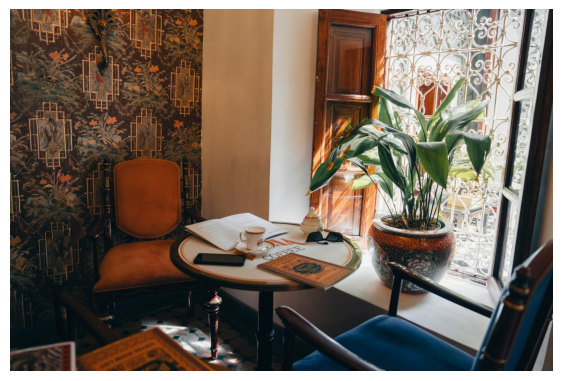

In [3]:
url_room = 'https://images.unsplash.com/photo-1760681557777-bfac1f18cf90?ixlib=rb-4.1.0&auto=format&fit=crop&q=80&w=2070'
image_path_room = DATA / 'room.jpg'
if not image_path_room.exists():
    urllib.request.urlretrieve(url_room, image_path_room)

url_bus = 'https://ultralytics.com/images/bus.jpg'
image_path_bus = DATA / 'bus.jpg'
if not image_path_bus.exists():
    urllib.request.urlretrieve(url_bus, image_path_bus)

image_room = np.array(Image.open(image_path_room).convert('RGB'))
print(f'image shape : {image_room.shape}   height, width, channels')

plt.figure(figsize=(7, 5))
plt.imshow(image_room)
plt.axis('off')
plt.show()

---
## Step 1. Running the Segmentation Model

- `yolo11n-seg` → the segmentation twin of `yolo11n`, the same 80 COCO classes
- `retina_masks=True` → masks at the image size (the default is the smaller size the model ran at)
- `predict` and `result.plot()` work exactly as for the detector; the masks come on top of the boxes

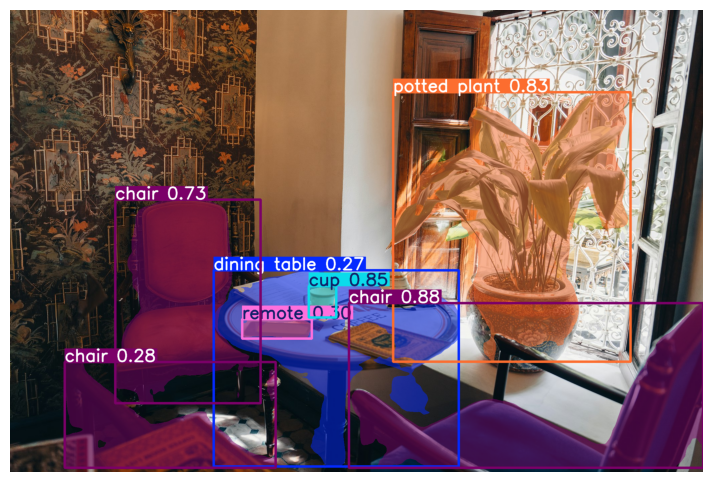

In [4]:
segmentation_model = YOLO(str(BUILD / 'yolo11n-seg.pt'))
segmentation_results = segmentation_model.predict(source=str(image_path_room), conf=0.25,
                                                  retina_masks=True, verbose=False)
segmentation_result = segmentation_results[0]  # we have only one result from one image

plt.figure(figsize=(9, 6))
plt.imshow(segmentation_result.plot()[:, :, ::-1])  # ::-1 reverses the channels, BGR -> RGB
plt.axis('off')
plt.show()

- Every object now has a box, a label and a coloured mask; `plot()` colours by class, so the chairs share one colour

---
## Step 2. What Is Inside `result.masks`

- `result.boxes` is the same as for the detector; `result.masks` is new

| Attribute | Shape | Meaning |
|:---|:---|:---|
| `boxes` | (N, 6) | `xyxy` · `conf` · `cls` per object, as for the detector |
| `masks.data` | (N, H, W) | one 0/1 grid per object, 1 inside |
| `masks.xy` | N arrays of (points, 2) | the outline of each mask in pixels |

In [5]:
print(f'boxes      : {tuple(segmentation_result.boxes.shape)}')
print(f'masks.data : {tuple(segmentation_result.masks.data.shape)}')
print(f'masks.xy   : {len(segmentation_result.masks.xy)} outlines, the first with {len(segmentation_result.masks.xy[0])} points')

boxes      : (7, 6)
masks.data : (7, 1380, 2070)
masks.xy   : 7 outlines, the first with 1101 points


- `result.names` → the 80 class names by index; one line per object with its confidence

In [6]:
for index in range(len(segmentation_result.boxes)):
    class_name = segmentation_result.names[int(segmentation_result.boxes.cls[index])]
    confidence = float(segmentation_result.boxes.conf[index])
    print(f'{class_name:<14s} {confidence:.3f}')

chair          0.882
cup            0.846
potted plant   0.835
chair          0.728
remote         0.296
chair          0.278
dining table   0.266


---
## Step 3. Drawing from the Mask

- `masks.data[0]` → the grid of the first object, 1 inside and 0 outside, the size of the image; `plot()` lays every grid on the image

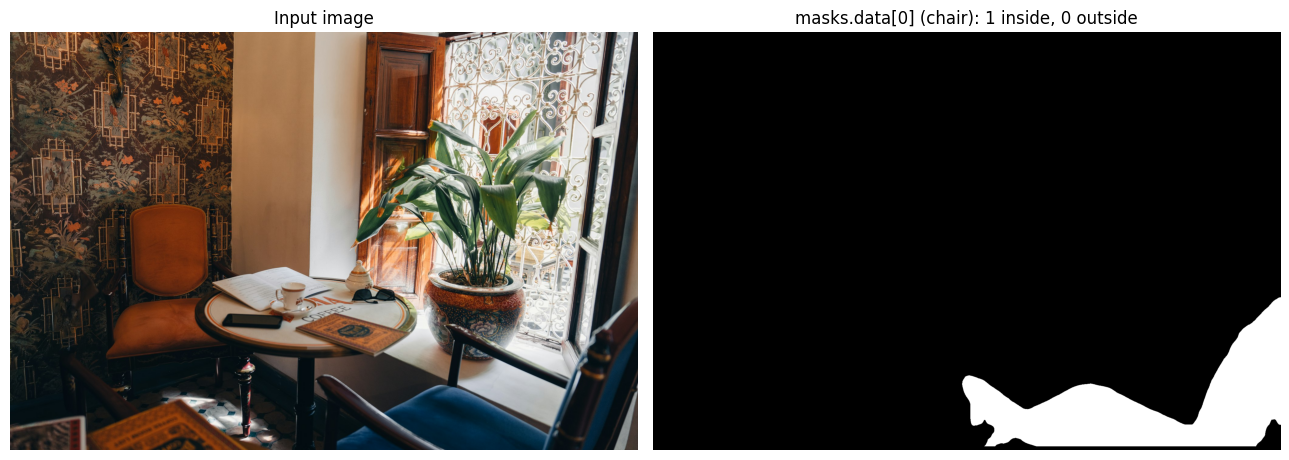

In [7]:
one_mask = segmentation_result.masks.data[0].cpu().numpy()
class_name = segmentation_result.names[int(segmentation_result.boxes.cls[0])]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].imshow(image_room)
axes[0].set_title('Input image')

axes[1].imshow(one_mask, cmap='gray')
axes[1].set_title(f'masks.data[0] ({class_name}): 1 inside, 0 outside')

for panel_axis in axes:
    panel_axis.axis('off')

plt.tight_layout()
plt.show()

- Box → where an object is; mask → which pixels are the object

---
## Step 4. The Confidence Threshold

- Only `conf` changes between the two calls → the masks that survive, their confidences in the labels

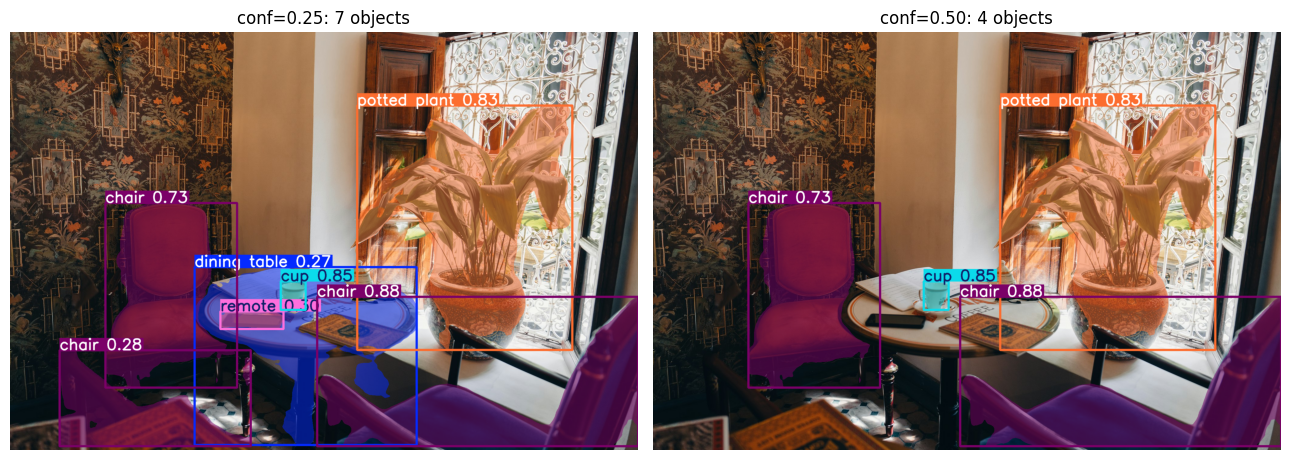

In [8]:
result_25 = segmentation_model.predict(source=str(image_path_room), conf=0.25, retina_masks=True, verbose=False)[0]
result_50 = segmentation_model.predict(source=str(image_path_room), conf=0.50, retina_masks=True, verbose=False)[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].imshow(result_25.plot()[:, :, ::-1])
axes[0].set_title(f'conf=0.25: {len(result_25.boxes)} objects')

axes[1].imshow(result_50.plot()[:, :, ::-1])
axes[1].set_title(f'conf=0.50: {len(result_50.boxes)} objects')

for panel_axis in axes:
    panel_axis.axis('off')

plt.tight_layout()
plt.show()

- Three detections sit below 0.50 (`remote`, a `chair`, `dining table`) → 7 masks become 4; the threshold works on the box confidence, each mask goes with its box

---
## Step 5. NMS

- NMS runs on the boxes, as for the detector → `iou=1.0` turns it off and shows every candidate above `conf`; each surviving box keeps its mask

iou=1.0 (NMS off) : 46 masks
iou=0.7 (default) :  7 masks


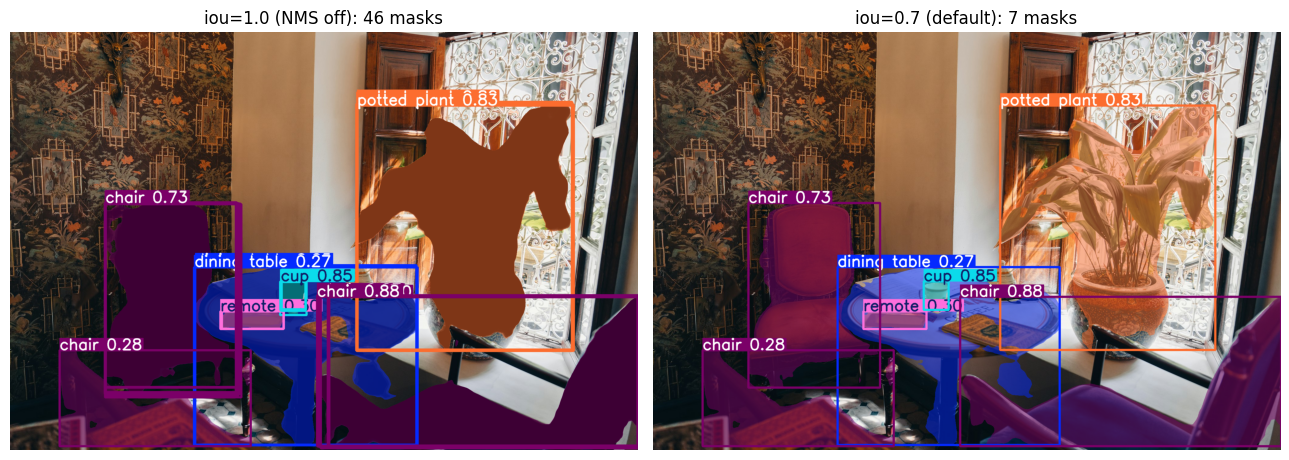

In [9]:
raw_result = segmentation_model.predict(source=str(image_path_room), conf=0.25, iou=1.0, retina_masks=True, verbose=False)[0]

print(f'iou=1.0 (NMS off) : {len(raw_result.boxes):2d} masks')
print(f'iou=0.7 (default) : {len(segmentation_result.boxes):2d} masks')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].imshow(raw_result.plot()[:, :, ::-1])
axes[0].set_title(f'iou=1.0 (NMS off): {len(raw_result.boxes)} masks')

axes[1].imshow(segmentation_result.plot()[:, :, ::-1])
axes[1].set_title(f'iou=0.7 (default): {len(segmentation_result.boxes)} masks')

for panel_axis in axes:
    panel_axis.axis('off')

plt.tight_layout()
plt.show()

- Left: 46 masks pass `conf=0.25`, many on the same object; right: one per object, the duplicates collapsed to the most confident box → the 7 of Step 1

---
## Step 6. Scoring the Segmentation Model: Box and Mask mAP

- Scoring needs labelled outlines → `coco8-seg`, the same 8 COCO images with outline labels, 4 for validation
- A segmentation label line = `class x1 y1 x2 y2 ... xn yn`, the outline points over the image size; a detector's label needs only the box
- The same three cells as for a detector: unzip, yaml, `val()`

coco8-seg/images/train  4 files
coco8-seg/images/val    4 files
coco8-seg/labels/train  4 files
coco8-seg/labels/val    4 files

000000000061.txt : 5 objects
first line        : class 0, 30 outline points


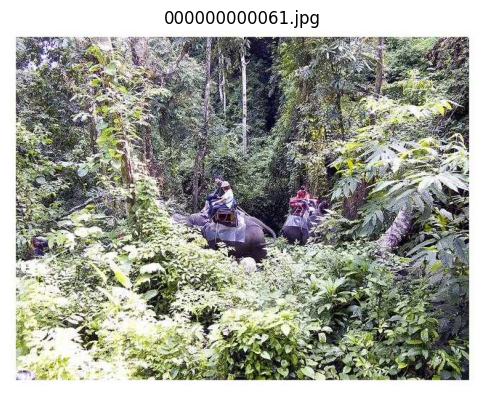

In [10]:
import zipfile

coco8_seg_dir = DATA / 'coco8-seg'
if not coco8_seg_dir.exists():
    urllib.request.urlretrieve(
        'https://github.com/ultralytics/assets/releases/download/v0.0.0/coco8-seg.zip', BUILD / 'coco8-seg.zip')
    with zipfile.ZipFile(BUILD / 'coco8-seg.zip') as archive:
        archive.extractall(DATA)

for folder in ['images/train', 'images/val', 'labels/train', 'labels/val']:
    n_files = len(list((coco8_seg_dir / folder).glob('*')))
    print(f'coco8-seg/{folder:<13s} {n_files} files')

label_path = coco8_seg_dir / 'labels' / 'val' / '000000000061.txt'
label_lines = label_path.read_text().strip().splitlines()
first_numbers = label_lines[0].split()
n_points = (len(first_numbers) - 1) // 2
print()
print(f'{label_path.name} : {len(label_lines)} objects')
print(f'first line        : class {first_numbers[0]}, {n_points} outline points')

plt.figure(figsize=(6, 6))
plt.imshow(Image.open(coco8_seg_dir / 'images' / 'val' / '000000000061.jpg'))
plt.title('000000000061.jpg')
plt.axis('off')
plt.show()

- The same five objects as in the detection labels, each now an outline instead of four box numbers; the first `person` takes 30 points

- The yaml is the same as for a detector → where the `train` and `val` images are, and what each class index means

In [11]:
coco8_seg_yaml_path = (DATA / 'coco8-seg.yaml').resolve()

# the two folders are written relative to the folder this file sits in
with open(coco8_seg_yaml_path, 'w', encoding='utf-8') as yaml_file:
    yaml_file.write('train: coco8-seg/images/train\n')
    yaml_file.write('val: coco8-seg/images/val\n')
    yaml_file.write('names:\n')
    for class_index, class_name in segmentation_model.names.items():
        yaml_file.write(f'  {class_index}: {class_name}\n')

# 83 lines: two folders, names:, then the 80 names
yaml_lines = coco8_seg_yaml_path.read_text().splitlines()
for line in yaml_lines[:5]:
    print(line)
print('  ...')
print(yaml_lines[-1])

train: coco8-seg/images/train
val: coco8-seg/images/val
names:
  0: person
  1: bicycle
  ...
  79: toothbrush


- `val()` prints two tables now → `Box(P R mAP50 mAP50-95)` as for the detector and `Mask(...)`, where a prediction matches a label by the IoU of the two pixel regions
- `box.map50` · `seg.map50` → the two totals; `split` and `name` work as before

In [12]:
seg_metrics = segmentation_model.val(data=str(coco8_seg_yaml_path), split='val', name='coco8-seg')  # or split='train' / 'test'

print()
print(f'box  mAP@50 : {seg_metrics.box.map50:.3f}')
print(f'mask mAP@50 : {seg_metrics.seg.map50:.3f}')

Ultralytics 8.4.194  Python-3.11.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA TITAN RTX, 24576MiB)


YOLO11n-seg summary (fused): 113 layers, 2,868,664 parameters, 0 gradients, 9.8 GFLOPs


val: Fast image access  (ping: 0.2±0.0 ms, read: 121.9±174.3 MB/s, size: 54.0 KB)


val: Scanning D:\Main\00_Research\00_Python\00_Lecture\03_Advanced_AI-ME_Graduate\data\coco8-seg\labels\val... 4 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4 796.1it/s 0.0s

val: New cache created: D:\Main\00_Research\00_Python\00_Lecture\03_Advanced_AI-ME_Graduate\data\coco8-seg\labels\val.cache


...

              umbrella          1          1      0.672          1      0.995      0.995      0.672          1      0.995      0.895


          potted plant          1          1      0.928          1      0.995      0.895      0.928          1      0.995      0.895


Speed: 0.3ms preprocess, 14.6ms inference, 0.0ms loss, 2.4ms postprocess per image


Results saved to D:\Main\00_Research\00_Python\00_Lecture\03_Advanced_AI-ME_Graduate\runs\segment\coco8-seg



box  mAP@50 : 0.887
mask mAP@50 : 0.852


- Box 0.887 and mask 0.852 sit close → when a box is right, its mask usually is too; the mask score is the stricter one (0.674 vs 0.571 at @50-95), a region must match pixel by pixel

- The run folder holds a precision–recall curve for the boxes and one for the masks

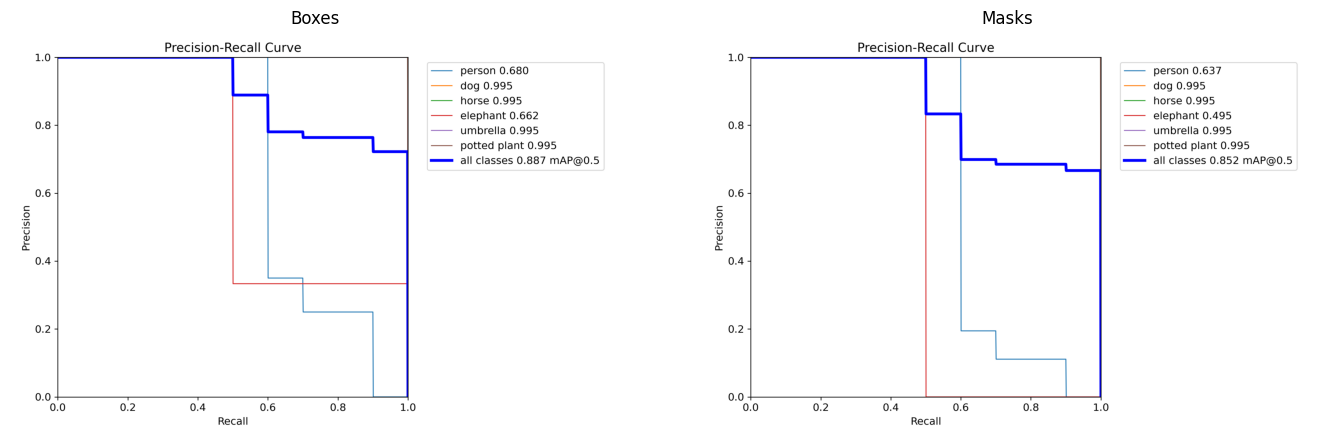

In [13]:
val_dir = Path(seg_metrics.save_dir)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].imshow(Image.open(val_dir / 'BoxPR_curve.png'))
axes[0].set_title('Boxes')

axes[1].imshow(Image.open(val_dir / 'MaskPR_curve.png'))
axes[1].set_title('Masks')

for panel_axis in axes:
    panel_axis.axis('off')

plt.tight_layout()
plt.show()

- A model that is not a YOLO → `torchmetrics` (`MeanAveragePrecision(iou_type='segm')`) or COCO's official `pycocotools` score masks the same way

---
## Step 7. What the Mask Buys You

- A mask gives the object's pixel count, a box only its extent
- Mask pixels / box pixels → how much of its box the object fills

In [14]:
print('object          mask pixels   box pixels   fill')
for index in range(len(segmentation_result.boxes)):
    class_index = int(segmentation_result.boxes.cls[index])
    x1, y1, x2, y2 = segmentation_result.boxes.xyxy[index].cpu().numpy()
    box_pixels = (x2 - x1) * (y2 - y1)
    mask_pixels = float(segmentation_result.masks.data[index].cpu().numpy().sum())
    fill = mask_pixels / box_pixels
    print(f'{segmentation_result.names[class_index]:<14s} {mask_pixels:11.0f} {box_pixels:12.0f}   {fill:.3f}')

object          mask pixels   box pixels   fill
chair               201373       520294   0.387
cup                   6389         7695   0.830
potted plant        279713       570222   0.491
chair               161082       264121   0.610
remote               10546        12171   0.866
chair               100735       199094   0.506
dining table        164716       428606   0.384


- Compact objects fill their box (`cup` 0.83, `remote` 0.87); wide or hollow ones do not (chairs, plant, table 0.38–0.61)
- Low fill → the box is mostly background

---
## Step 8. The Same Call on Another Image

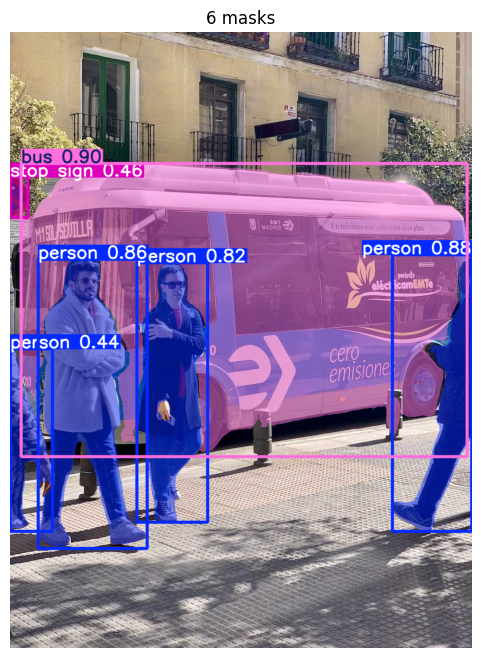

In [15]:
segmentation_bus = segmentation_model.predict(source=str(image_path_bus), conf=0.25,
                                              retina_masks=True, verbose=False)[0]

plt.figure(figsize=(7, 8))
plt.imshow(segmentation_bus.plot()[:, :, ::-1])
plt.title(f'{len(segmentation_bus.boxes)} masks')
plt.axis('off')
plt.show()

- 6 masks: the bus, four people and the round sign at the left edge, labelled `stop sign` at 0.46, the nearest COCO class

---
## Summary

| Result | Holds | Note |
|:---|:---|:---|
| Segmentation | `boxes` as for a detector, plus `masks.data` (N, H, W) and `masks.xy` | `retina_masks=True` → grids at the image size |
| `conf` · NMS | the same arguments, applied to the boxes | each mask follows its box |
| mAP | `val()` on outline labels | a Box table and a Mask table |
| Fill | mask pixels / box pixels | how much of the box is object |

---
## Exercises

1. `conf=0.7`, rerun Step 4 — which masks remain, and what were their confidences?
2. Rerun `val()` with `split='train'` — do the box and mask scores move together?
3. Draw only the object with the largest mask area, using the pixel counts of Step 7.

In [16]:
# Write your code here